In [69]:
import pandas as pd
import numpy as np
import re
sncf_data = pd.read_csv("project_dataset.csv", sep=";")

np.random.seed(0)
sncf_data.head()
sncf_data.shape
sncf_data.info()
sncf_data.describe()
sncf_data.duplicated().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12070 entries, 0 to 12069
Data columns (total 26 columns):
 #   Column                                                                                       Non-Null Count  Dtype 
---  ------                                                                                       --------------  ----- 
 0   Date                                                                                         12010 non-null  object
 1   Service                                                                                      11830 non-null  object
 2   Gare de dÃ©part                                                                              12011 non-null  object
 3   Gare d'arrivÃ©e                                                                              12011 non-null  object
 4   DurÃ©e moyenne du trajet                                                                     11830 non-null  object
 5   Nombre de circulations prÃ©vues        

np.int64(174)

# rename noms colonnes 

In [70]:
rename_map = {
    "Date": "Date",
    "Service": "Service",

    "Gare de dÃ©part": "Gare de départ",
    "Gare d'arrivÃ©e": "Gare d'arrivée",

    "DurÃ©e moyenne du trajet": "Durée moyenne du trajet",
    "Nombre de circulations prÃ©vues": "Nombre de circulations prévues",
    "Nombre de trains annulÃ©s": "Nombre de trains annulés",
    "Commentaire annulations": "Commentaire annulations",

    "Nombre de trains en retard au dÃ©part": "Nombre de trains en retard au départ",
    "Retard moyen des trains en retard au dÃ©part": "Retard moyen des trains en retard au départ",
    "Retard moyen de tous les trains au dÃ©part": "Retard moyen de tous les trains au départ",
    "Commentaire retards au dÃ©part": "Commentaire retards au départ",

    "Nombre de trains en retard Ã  l'arrivÃ©e": "Nombre de trains en retard à l'arrivée",
    "Retard moyen des trains en retard Ã  l'arrivÃ©e": "Retard moyen des trains en retard à l'arrivée",
    "Retard moyen de tous les trains Ã  l'arrivÃ©e": "Retard moyen de tous les trains à l'arrivée",
    "Commentaire retards Ã  l'arrivÃ©e": "Commentaire retards à l'arrivée",

    "Nombre trains en retard > 15min": "Nombre trains en retard > 15min",
    "Retard moyen trains en retard > 15 (si liaison concurrencÃ©e par vol)":
        "Retard moyen trains en retard > 15 (si liaison concurrencée par vol)",

    "Nombre trains en retard > 30min": "Nombre trains en retard > 30min",
    "Nombre trains en retard > 60min": "Nombre trains en retard > 60min",

    "Prct retard pour causes externes": "Prct retard pour causes externes",
    "Prct retard pour cause infrastructure": "Prct retard pour cause infrastructure",
    "Prct retard pour cause gestion trafic": "Prct retard pour cause gestion trafic",
    "Prct retard pour cause matÃ©riel roulant": "Prct retard pour cause matériel roulant",
    "Prct retard pour cause gestion en gare et rÃ©utilisation de matÃ©riel":
        "Prct retard pour cause gestion en gare et réutilisation de matériel",
    "Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)":
        "Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)",
}

sncf_data = sncf_data.rename(columns=rename_map)
print(sncf_data.columns.tolist)

<bound method IndexOpsMixin.tolist of Index(['Date', 'Service', 'Gare de départ', 'Gare d'arrivée',
       'Durée moyenne du trajet', 'Nombre de circulations prévues',
       'Nombre de trains annulés', 'Commentaire annulations',
       'Nombre de trains en retard au départ',
       'Retard moyen des trains en retard au départ',
       'Retard moyen de tous les trains au départ',
       'Commentaire retards au départ',
       'Nombre de trains en retard à l'arrivée',
       'Retard moyen des trains en retard à l'arrivée',
       'Retard moyen de tous les trains à l'arrivée',
       'Commentaire retards à l'arrivée', 'Nombre trains en retard > 15min',
       'Retard moyen trains en retard > 15 (si liaison concurrencée par vol)',
       'Nombre trains en retard > 30min', 'Nombre trains en retard > 60min',
       'Prct retard pour causes externes',
       'Prct retard pour cause infrastructure',
       'Prct retard pour cause gestion trafic',
       'Prct retard pour cause matériel roulan

In [71]:
# Remplir les colonnes "Nombre ..." manquantes(NaN) par 0 (logique : pas de train compté)
count_cols = [c for c in sncf_data.columns if c.startswith("Nombre")]
for c in count_cols:
    sncf_data[c] = sncf_data[c].fillna(0)

In [72]:
sncf_data[count_cols].isna().sum().sort_values(ascending=False).head(10)

Nombre de circulations prévues            0
Nombre de trains annulés                  0
Nombre de trains en retard au départ      0
Nombre de trains en retard à l'arrivée    0
Nombre trains en retard > 15min           0
Nombre trains en retard > 30min           0
Nombre trains en retard > 60min           0
dtype: int64

# Creation Filtre pour DATASET CLEAN 

In [73]:
import re 
#fix noms de colonnes (accents)

def fixaccent(s):
    try:
        return s.encode("latin1").decode("utf-8")
    except Exception:
        return s
sncf_data.columns = [fixaccent(c) for c in sncf_data.columns]
#drop les colonnes commentaire 
comment_cols = [c for c in sncf_data.columns if "Commentaire" in c]
sncf_data = sncf_data.drop(columns=comment_cols, errors="ignore")

#nettoyage colonnes texte 
text_cols = ["Service", "Gare de départ", "Gare d'arrivée"]
for c in text_cols:
    if c in sncf_data.columns:
        sncf_data[c] = sncf_data[c].astype("string").str.strip()

# standardisation gares (pour évite "Paris Montparnasse" vs "PARIS MONTPARNASSE")
for c in ["Gare de départ", "Gare d'arrivée"]:
    if c in sncf_data.columns:
        sncf_data[c] = sncf_data[c].str.upper().str.replace(r"\s+", " ", regex=True)

# 3) Nettoyage Date (formats mixtes: 2018-01, 01-2018, 2018/01, espaces)
def parse_month(s: pd.Series) -> pd.Series:
    x = s.astype("string").str.strip().str.replace("/", "-", regex=False)
    m = x.str.match(r"^\d{2}-\d{4}$", na=False)
    x.loc[m] = x.loc[m].str.split("-", expand=True).apply(lambda r: f"{r[1]}-{r[0]}", axis=1)
    return pd.to_datetime(x, format="%Y-%m", errors="coerce")

sncf_data["Date"] = parse_month(sncf_data["Date"])
sncf_data["year"] = sncf_data["Date"].dt.year
sncf_data["month"] = sncf_data["Date"].dt.month


# Chek doublon 

In [74]:
duplicata_test= sncf_data.duplicated().sum()
print("Doublons :", duplicata_test)
#donc
sncf_data = sncf_data.drop_duplicates(keep="first").copy()
print("Nouvelles dimensions:", sncf_data.shape)

Doublons : 226
Nouvelles dimensions: (11844, 25)


# Clean les donnée numérique 

In [75]:
NA_LIKE = {"NC", "Non communiqué", "NON COMMUNIQUE", "-", ""}

def to_float(series: pd.Series) -> pd.Series:
    s = series.astype("string").str.strip()
    s = s.replace(list(NA_LIKE), np.nan)

    # enlever "min", gérer virgules, espaces
    s = (s.str.lower()
           .str.replace("min", "", regex=False)
           .str.replace(",", ".", regex=False)
           .str.replace(r"\s+", "", regex=True))

    # extraire le nombre (safe)
    s = s.str.extract(r"(-?\d+(?:\.\d+)?)")[0]
    return pd.to_numeric(s, errors="coerce")

# Colonnes à convertir = tout sauf texte/date
exclude = {"Date", "Service", "Gare de départ", "Gare d'arrivée"}
num_cols = [c for c in sncf_data.columns if c not in exclude and c not in ("year", "month")]

for c in num_cols:
    sncf_data[c] = to_float(sncf_data[c])

# Missing Value

In [76]:
#Avant de commencer on fait un gros clean des donnes Nul donv NaN  
#On regarde ce qui manque par colonne pour se faire une idée , en % aussi 
missing = sncf_data.isna().sum().sort_values(ascending=False)
total_missing = missing.sum()

report = pd.DataFrame({
    "missing_count": missing,
    "missing_pct_col": sncf_data.isna().mean() * 100,
})

display(report.head(15))
#On remarquera que les commentaire on beaucoup de missing value ce qui est
#  logique , puis en regardant ce que contient les commentaire on se rend 
# compte qu'il y a pas d'interet a garder ces data

,missing_count,missing_pct_col
Date,154,1.300236
Durée moyenne du trajet,236,1.992570
Gare d'arrivée,59,0.498143
Gare de départ,59,0.498143
Nombre de circulations prévues,0,0.000000
Nombre de trains annulés,0,0.000000
Nombre de trains en retard au départ,0,0.000000
Nombre de trains en retard à l'arrivée,0,0.000000
Nombre trains en retard > 15min,0,0.000000
Nombre trains en retard > 30min,0,0.000000


## Why are they Missing ? Any correlation?


In [77]:
#avant on a remarqué qu'il y a chaque fois a peu pres 240 valeur nul donc pour êtres sure de ne pas passer a cote de qlq chose qu on pourrai remplacer au lieu de supprimer betement
cols = sncf_data.columns.difference(exclude).tolist()

mask = sncf_data[cols].isna()
# Combien de lignes ont au moins 1 NA dans ces colonnes?
print("Row with any NA:", mask.any(axis=1).sum())
# Combien de lignes ont TOUS ces champs en NA?
print("ROws with ALL NA:", mask.all(axis=1).sum())
# Ya combien de NA par ligne sur ces colones dcp
print(mask.sum(axis=1).value_counts().head(10))

Row with any NA: 2678
ROws with ALL NA: 0
0    9166
1    2268
2     360
3      47
4       3
Name: count, dtype: int64


In [78]:
# Est-ce que les NaN des "retards moyens" arrivent surtout quand le nombre de trains en retard = 0 ?

dep_count = [c for c in sncf_data.columns if "Nombre de trains en retard au départ" in c]
arr_count = [c for c in sncf_data.columns if "Nombre de trains en retard à l'arrivée" in c]
mean_cols = [c for c in sncf_data.columns if "Retard moyen" in c]

if dep_count:
    dep_count = dep_count[0]
if arr_count:
    arr_count = arr_count[0]

rows = []
for col in mean_cols:
    if "départ" in col and isinstance(dep_count, str):
        mask0 = sncf_data[dep_count].fillna(0) == 0
    elif "arrivée" in col and isinstance(arr_count, str):
        mask0 = sncf_data[arr_count].fillna(0) == 0
    else:
        continue

    na_rate_0 = sncf_data.loc[mask0, col].isna().mean() * 100
    na_rate_1 = sncf_data.loc[~mask0, col].isna().mean() * 100
    rows.append([col, round(na_rate_0, 2), round(na_rate_1, 2)])

pd.DataFrame(rows, columns=["col", "NA% when count=0", "NA% when count>0"]).sort_values("NA% when count=0", ascending=False)

,col,NA% when count=0,NA% when count>0
2,Retard moyen des trains en retard à l'arrivée,2.78,1.96
1,Retard moyen de tous les trains au départ,2.17,1.99
0,Retard moyen des trains en retard au départ,1.63,2.00
3,Retard moyen de tous les trains à l'arrivée,0.69,2.04


# Test Logique sncf


In [79]:
#tchek si c'est pas tout simplement liée car de base le nombre de train = 0,(donc tout ce qui peut etres lié a la racine du retard)
mean_cols = [c for c in sncf_data.columns if "Retard moyen" in c]
count_cols = [c for c in sncf_data.columns if "Nombre" in c and "retard" in c.lower()]

print("mean_cols:", len(mean_cols))
print("count_cols:", len(count_cols))

mean_cols: 5
count_cols: 5


# Resultat trop petit , on ne prendra pas en compte ce test

In [80]:


df = sncf_data.copy()

#  On ignore les colonnes "Commentaire" (quasi vides / inutiles)
comment_cols = [c for c in df.columns if "Commentaire" in c]
df2 = df.drop(columns=comment_cols, errors="ignore")

n_rows = len(df2)

#  Impact d'un dropna global (sur le dataset utile)
after_drop_all = df2.dropna()
pct_kept_all = 100 * len(after_drop_all) / n_rows

# Distribution des NaN par ligne (dataset utile)
na_per_row = df2.isna().sum(axis=1)
max_na = int(na_per_row.max())
pct_rows_any_na = 100 * (na_per_row.gt(0).mean())

# Colonnes les plus touchées (hors commentaires)
missing_summary = (
    pd.DataFrame({
        "missing_count": df2.isna().sum(),
        "missing_pct": df2.isna().mean() * 100
    })
    .query("missing_count > 0")
    .sort_values("missing_count", ascending=False)
)

print("Missingness report (hors colonnes Commentaire) ")
print(f"Rows total: {n_rows}")
print(f"Rows with any NA: {na_per_row.gt(0).sum()} ({pct_rows_any_na:.1f}%)")
print(f"Max NA per row: {max_na}")
print("\nTop NA-per-row distribution:")
print(na_per_row.value_counts().head(10))

print("\n=== Why we do NOT use dropna() globally ===")
print(f"Rows kept after df.dropna(): {len(after_drop_all)} / {n_rows} ({pct_kept_all:.2f}%)")
print(" Global dropna() would discard too much data, while missing values are sparse (max 4 per row).")
print("\nTop columns with missing values:")
print(missing_summary.head(15))

Missingness report (hors colonnes Commentaire) 
Rows total: 11844
Rows with any NA: 2948 (24.9%)
Max NA per row: 5

Top NA-per-row distribution:
0    8896
1    2474
2     296
3     132
4      43
5       3
Name: count, dtype: int64

=== Why we do NOT use dropna() globally ===
Rows kept after df.dropna(): 8896 / 11844 (75.11%)
 Global dropna() would discard too much data, while missing values are sparse (max 4 per row).

Top columns with missing values:
                                                    missing_count  missing_pct
Prct retard pour cause gestion en gare et réuti...            237     2.001013
Service                                                       236     1.992570
Prct retard pour cause matériel roulant                       236     1.992570
Retard moyen des trains en retard au départ                   236     1.992570
Retard moyen des trains en retard à l'arrivée                 236     1.992570
Durée moyenne du trajet                                       236     

## Après suppression des colonnes Commentaire, les valeurs manquantes restent éparses (max 4 NaN par ligne) mais touchent ~34% des lignes. Un dropna() global supprimerait une part importante du dataset (≈ un tiers), donc nous privilégions une stratégie de prétraitement + imputation plutôt que la suppression des lignes 

# Test display


In [81]:
display(sncf_data.head(30))
display(sncf_data.tail(30))

,Date,Service,Gare de départ,Gare d'arrivée,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,Retard moyen de tous les trains au départ,...,Nombre trains en retard > 30min,Nombre trains en retard > 60min,Prct retard pour causes externes,Prct retard pour cause infrastructure,Prct retard pour cause gestion trafic,Prct retard pour cause matériel roulant,Prct retard pour cause gestion en gare et réutilisation de matériel,"Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)",year,month
0,2018-01-01,National,BORDEAUX ST JEAN,PARIS MONTPARNASSE,141.0,870.0,5.0,289.0,11.247809,3.693179,...,44.0,8.0,36.134454,31.092437,10.92437,15.966387,5.04,0.840336,2018.0,1.0
1,2018-01-01,National,LE MANS,PARIS MONTPARNASSE,56.0,406.0,1.0,213.0,8.479969,4.567119,...,9.0,4.0,20.0,35.0,16.666667,16.666667,8.333333,3.333333,2018.0,1.0
2,2018-01-01,National,PARIS MONTPARNASSE,LA ROCHELLE VILLE,166.0,226.0,0.0,21.0,6.239683,0.286283,...,6.0,1.0,22.222222,27.777778,16.666667,16.666667,5.555556,11.111111,2018.0,1.0
3,2018-01-01,National,PARIS MONTPARNASSE,NANTES,216.21,508.0,3.0,71.0,7.235211,0.98,...,18.0,0.0,33.333333,22.222222,16.666667,20.37037,5.555556,1.851852,2018.0,1.0
4,2018-01-01,National,POITIERS,PARIS MONTPARNASSE,94.0,472.0,4.0,224.0,6.784673,3.229701,...,10.0,0.0,15.789474,45.614035,<NA>,15.789474,1.754386,1.754386,2018.0,1.0
5,2018-01-01,National,ST MALO,PARIS MONTPARNASSE,158.0,92.0,0.0,2.0,1.225,0.0625,...,3.0,1.0,22.222222,66.666667,0.0,11.111111,0.0,0.0,2018.0,1.0
6,2018-01-01,National,TOULOUSE MATABIAU,PARIS MONTPARNASSE,257.0,184.0,0.0,0.0,11.221739,1.193931,...,12.0,3.0,59.090909,22.727273,4.545455,9.090909,4.545455,0.0,2018.0,1.0
7,2018-01-01,National,VANNES,PARIS MONTPARNASSE,156.0,278.0,1.0,168.0,5.120437,3.131047,...,11.0,3.0,24.137931,44.827586,20.689655,3.448,3.448276,3.448276,2018.0,1.0
8,2018-01-01,National,REIMS,PARIS EST,46.0,230.0,1.0,93.0,7.4,3.107569,...,3.0,0.0,17.948718,41.025641,20.512821,5.128205,0.0,15.384615,2018.0,1.0
9,2018-01-01,National,DOUAI,PARIS NORD,77.0,197.0,3.0,39.0,8.032906,1.802921,...,5.0,3.0,36.363636,18.181818,22.727273,18.181818,4.545455,0.0,2018.0,1.0


,Date,Service,Gare de départ,Gare d'arrivée,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,Retard moyen de tous les trains au départ,...,Nombre trains en retard > 30min,Nombre trains en retard > 60min,Prct retard pour causes externes,Prct retard pour cause infrastructure,Prct retard pour cause gestion trafic,Prct retard pour cause matériel roulant,Prct retard pour cause gestion en gare et réutilisation de matériel,"Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)",year,month
11814,2025-12-01,National,BREST,PARIS MONTPARNASSE,226.0,286.0,1.0,16.0,10.531,0.621053,...,9.0,2.0,26.923077,26.923077,23.076923,11.538462,3.846154,7.692308,2025.0,12.0
11815,2025-12-01,National,LILLE,MARSEILLE ST CHARLES,296.0,250.0,1.0,89.0,15.557865,5.539023,...,31.0,15.0,7.692308,12.307692,32.307692,16.923077,12.307692,18.461538,2025.0,12.0
11816,2025-12-01,National,LILLE,PARIS NORD,71.0,566.0,4.0,142.0,8.864085,2.04831,...,22.0,4.0,8.333333,21.077128,31.582447,15.802305,16.910461,6.294326,2025.0,12.0
11817,2025-12-01,National,LYON PART DIEU,PARIS LYON,119.0,638.0,3.0,301.0,9.533555,4.640525,...,36.0,0.0,5.331263,8.540373,39.311594,20.238095,15.967909,10.610766,2025.0,12.0
11818,2025-12-01,National,LYON PART DIEU,RENNES,237.0,93.0,0.0,35.0,8.742857,3.524194,...,4.0,2.0,30.0,10.0,30.0,20.0,0.0,10.0,2025.0,12.0
11819,2025-12-01,National,MARNE LA VALLEE,LYON PART DIEU,106.0,408.0,1.0,257.0,15.198119,9.731654,...,40.0,17.0,7.820954,13.043122,26.10264,31.283817,20.872274,0.877193,2025.0,12.0
11820,2025-12-01,National,MONTPELLIER,LYON PART DIEU,114.0,181.0,2.0,46.0,11.513406,3.040596,...,6.0,1.0,11.764706,14.705882,47.06,2.941176,17.647059,5.882353,2025.0,12.0
11821,2025-12-01,National,MONTPELLIER,PARIS LYON,<NA>,186.0,0.0,61.0,18.471858,6.107437,...,14.0,7.0,<NA>,17.241379,48.275862,3.448276,13.793103,3.448276,2025.0,12.0
11822,2025-12-01,National,NICE VILLE,PARIS LYON,350.0,188.0,1.0,27.0,26.225926,3.602496,...,24.0,11.0,<NA>,13.474026,33.603896,10.876623,10.714286,8.928571,2025.0,12.0
11823,2025-12-01,<NA>,PARIS EST,METZ,84.0,273.0,0.0,30.0,10.900556,1.183211,...,5.0,1.0,20.0,20.0,23.809524,8.571429,24.761905,2.857143,2025.0,12.0


In [82]:
# Colonnes texte suspectes (avec chiffres / min / virgules)
sus = []
for c in df.select_dtypes(include=["object","string"]).columns:
    s = df[c].astype("string")
    if s.str.contains(r"\bmin\b|,|NC|\d", regex=True, na=False).any():
        sus.append(c)

print("Text cols suspectes:", sus)
for c in sus:
    print("\n---", c, "---")
    print(df[c].dropna().head(10).tolist())

Text cols suspectes: ['Gare de départ', "Gare d'arrivée"]

--- Gare de départ ---
['BORDEAUX ST JEAN', 'LE MANS', 'PARIS MONTPARNASSE', 'PARIS MONTPARNASSE', 'POITIERS', 'ST MALO', 'TOULOUSE MATABIAU', 'VANNES', 'REIMS', 'DOUAI']

--- Gare d'arrivée ---
['PARIS MONTPARNASSE', 'PARIS MONTPARNASSE', 'LA ROCHELLE VILLE', 'NANTES', 'PARIS MONTPARNASSE', 'PARIS MONTPARNASSE', 'PARIS MONTPARNASSE', 'PARIS MONTPARNASSE', 'PARIS EST', 'PARIS NORD']


In [83]:
raw = pd.read_csv("project_dataset.csv", sep=";", usecols=["Date"], dtype=str)
raw_bad = raw[raw["Date"].isna() | ~raw["Date"].str.contains(r"\d", na=False)]
raw["Date"].value_counts(dropna=False).head(150)

Date
2025-09     135
2025-07     134
2018-04     134
2025-08     132
2018-02     131
           ... 
2023-10       2
2024/03       2
2024 03       2
2019-03       2
03-2023       2
Name: count, Length: 150, dtype: int64

In [84]:
clean_path = "dataset_clean.csv"
df.to_csv(clean_path, sep=";", index=False, encoding="utf-8")
print("ecrit: ", clean_path)

ecrit:  dataset_clean.csv


In [85]:
missing = sncf_data.isna().sum()
missing[missing > 0].sort_values(ascending=False)

Prct retard pour cause gestion en gare et réutilisation de matériel                            237
Service                                                                                        236
Prct retard pour cause matériel roulant                                                        236
Retard moyen des trains en retard au départ                                                    236
Retard moyen des trains en retard à l'arrivée                                                  236
Durée moyenne du trajet                                                                        236
Retard moyen de tous les trains à l'arrivée                                                    236
Retard moyen trains en retard > 15 (si liaison concurrencée par vol)                           236
Prct retard pour causes externes                                                               236
Retard moyen de tous les trains au départ                                                      236
Prct retar

In [86]:
sncf_data.isna().sum().sum()  # total de NA dans tout le DF

np.int64(3649)

In [87]:
sncf_data = sncf_data.dropna(subset=["Date", "Gare de départ", "Gare d'arrivée"])

sncf_data["year"] = sncf_data["Date"].dt.year
sncf_data["month"] = sncf_data["Date"].dt.month

In [88]:
sncf_data["Service"] = sncf_data["Service"].fillna("UNKNOWN")

In [89]:
dep_count = [c for c in sncf_data.columns if "Nombre de trains en retard" in c and "départ" in c.lower()]
arr_count = [c for c in sncf_data.columns if "Nombre de trains en retard" in c and "arriv" in c.lower()]

dep_count = dep_count[0] if dep_count else None
arr_count = arr_count[0] if arr_count else None

pct_cols = [c for c in sncf_data.columns if c.startswith("Prct retard")]
mean_cols = [c for c in sncf_data.columns if c.startswith("Retard moyen")]

mask0 = None
if dep_count and arr_count:
    mask0 = (sncf_data[dep_count].fillna(0) == 0) & (sncf_data[arr_count].fillna(0) == 0)
elif dep_count:
    mask0 = (sncf_data[dep_count].fillna(0) == 0)
elif arr_count:
    mask0 = (sncf_data[arr_count].fillna(0) == 0)

if mask0 is not None:
    sncf_data.loc[mask0, mean_cols] = sncf_data.loc[mask0, mean_cols].fillna(0)
    sncf_data.loc[mask0, pct_cols] = sncf_data.loc[mask0, pct_cols].fillna(0)

In [90]:
missing = sncf_data.isna().sum()
missing[missing > 0].sort_values(ascending=False)

Retard moyen de tous les trains à l'arrivée                                                    233
Durée moyenne du trajet                                                                        232
Prct retard pour cause gestion trafic                                                          232
Retard moyen des trains en retard au départ                                                    230
Prct retard pour causes externes                                                               230
Retard moyen des trains en retard à l'arrivée                                                  230
Prct retard pour cause gestion en gare et réutilisation de matériel                            229
Prct retard pour cause matériel roulant                                                        228
Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)    228
Retard moyen trains en retard > 15 (si liaison concurrencée par vol)                           228
Retard moy

Colonnes dispo : Index(['Date', 'Service', 'Gare de départ', 'Gare d'arrivée',
       'Durée moyenne du trajet', 'Nombre de circulations prévues',
       'Nombre de trains annulés', 'Nombre de trains en retard au départ',
       'Retard moyen des trains en retard au départ',
       'Retard moyen de tous les trains au départ',
       'Nombre de trains en retard à l'arrivée',
       'Retard moyen des trains en retard à l'arrivée',
       'Retard moyen de tous les trains à l'arrivée',
       'Nombre trains en retard > 15min',
       'Retard moyen trains en retard > 15 (si liaison concurrencée par vol)',
       'Nombre trains en retard > 30min', 'Nombre trains en retard > 60min',
       'Prct retard pour causes externes',
       'Prct retard pour cause infrastructure',
       'Prct retard pour cause gestion trafic',
       'Prct retard pour cause matériel roulant',
       'Prct retard pour cause gestion en gare et réutilisation de matériel',
       'Prct retard pour cause prise en compte v

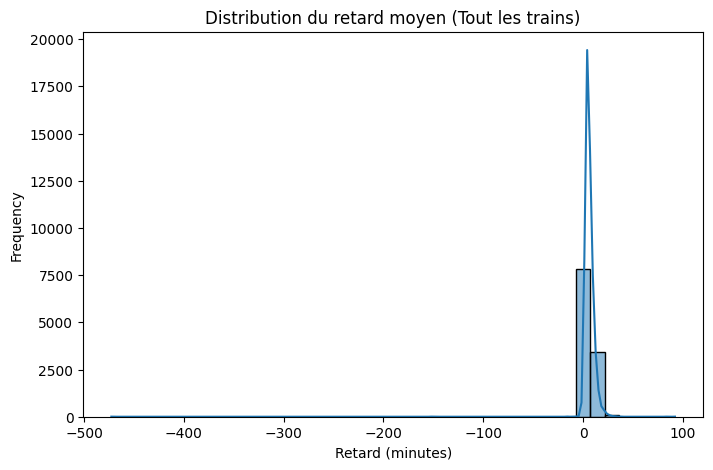

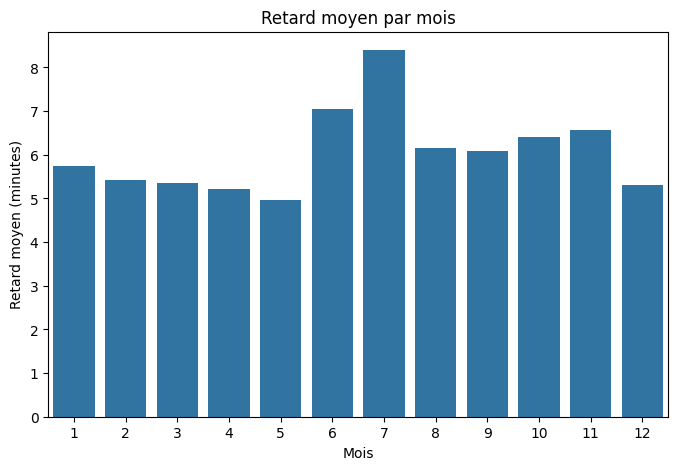

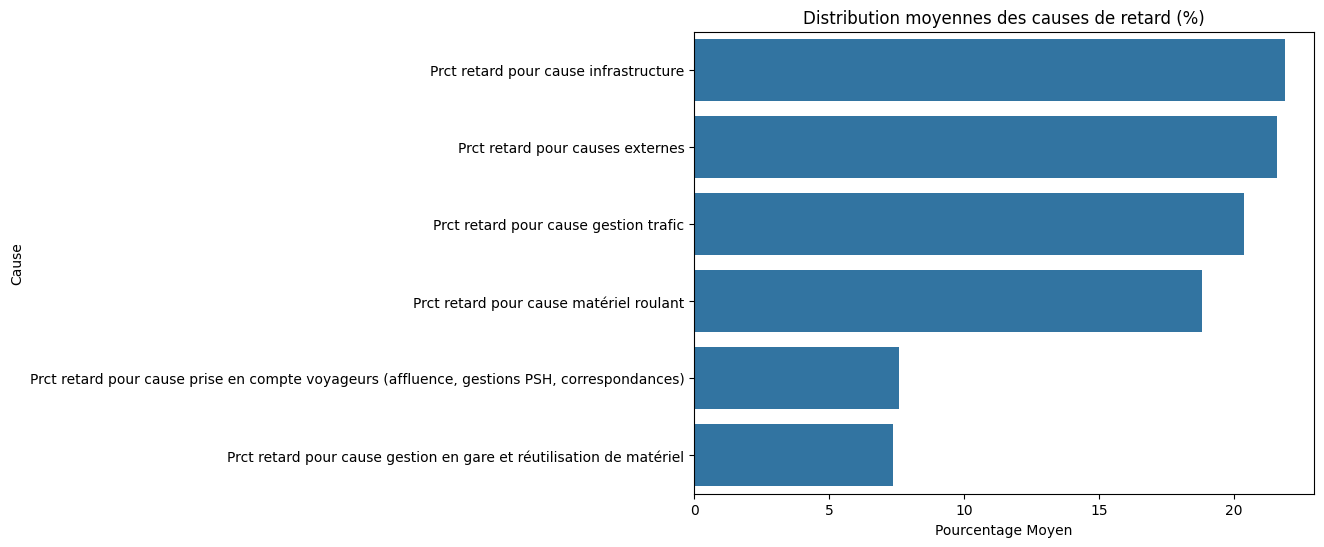

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Nettoyage colonnes (important)
sncf_data.columns = sncf_data.columns.str.strip()

# Vérifie que la colonne date existe pour créer month si besoin
if "month" not in sncf_data.columns:
    if "Date" in sncf_data.columns:
        sncf_data["Date"] = pd.to_datetime(sncf_data["Date"], errors="coerce")
        sncf_data["month"] = sncf_data["Date"].dt.month

# On stocke le nom de la target dans une variable pour éviter les erreurs
delay_col = "Retard moyen de tous les trains à l'arrivée"

print("Colonnes dispo :", sncf_data.columns)


# 1 Distribution des retards


plt.figure(figsize=(8, 5))
sns.histplot(
    sncf_data[delay_col],
    bins=40,
    kde=True
)

plt.title("Distribution du retard moyen (Tout les trains)")
plt.xlabel("Retard (minutes)")
plt.ylabel("Frequence")
plt.show()



# 2 Retard moyen par mois


monthly_delay = (
    sncf_data.groupby("month")[delay_col]
    .mean()
    .reset_index()
)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=monthly_delay,
    x="month",
    y=delay_col
)

plt.title("Retard moyen par mois")
plt.xlabel("Mois")
plt.ylabel("Retard moyen (minutes)")
plt.show()


# 3 Répartition des causes

cause_cols = [c for c in sncf_data.columns if "Prct retard" in c]

cause_means = (
    sncf_data[cause_cols]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 6))
sns.barplot(
    x=cause_means.values,
    y=cause_means.index
)

plt.title("Distribution moyennes des causes de retard (%)")
plt.xlabel("Pourcentage Moyen")
plt.ylabel("Cause")
plt.show()